# EdTech Learning Outcome Analytics

## Student Engagement Funnel & Dropout Prediction

### Day 1: Business Understanding and Dataset Exploration

**Dataset:** Open University Learning Analytics Dataset (OULAD)

**Objective:** Understand student engagement, learning behaviour, academic performance, retention, and withdrawal patterns to identify students at risk of dropping out.


## 1. Business Problem

Online learning platforms face a major challenge: not every student who enrolls in a course completes it successfully.

Students may register for a course but never become active, show low engagement with learning materials, miss assessments, gradually disengage, or withdraw before completing the course.

The objective of this project is to analyze the student learning journey and answer:

1. Where do students drop off in the learning journey?
2. Which engagement behaviours are associated with successful outcomes?
3. Which courses or student groups have higher withdrawal rates?
4. How does engagement change over time?
5. Can student behaviour and academic performance help identify students at risk of withdrawal?

## 2. Project Objectives

The objectives of this project are:

- Analyze student enrollment and final outcomes.
- Measure student engagement using Virtual Learning Environment (VLE) interactions.
- Build a student engagement funnel.
- Identify major student drop-off points.
- Compare course and student performance.
- Perform retention and cohort analysis.
- Segment students based on engagement and performance.
- Identify factors associated with student withdrawal.
- Build a model to predict dropout risk.
- Present key findings through an interactive Power BI dashboard.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

In [3]:
data_path = "../data/raw"

print("Files in raw data folder:")
print(os.listdir(data_path))

Files in raw data folder:
['assessments.csv', 'courses.csv', 'OULAD.names', 'studentAssessment.csv', 'studentInfo.csv', 'studentRegistration.csv', 'studentVle.csv', 'vle.csv']


In [7]:
courses = pd.read_csv("../data/raw/courses.csv")
assessments = pd.read_csv("../data/raw/assessments.csv")
student_assessment = pd.read_csv("../data/raw/studentAssessment.csv")
student_info = pd.read_csv("../data/raw/studentInfo.csv")
student_registration = pd.read_csv("../data/raw/studentRegistration.csv")
student_vle = pd.read_csv("../data/raw/studentVle.csv")
vle = pd.read_csv("../data/raw/vle.csv")

In [8]:
datasets = {
    "courses" : courses,
    "assessments" : assessments,
    "student_assessment" : student_assessment,
    "student_info" : student_info,
    "student_registration" : student_registration,
    "student_vle" : student_vle,
    "vle" : vle
} 

summary = pd.DataFrame({
    "Dataset" : datasets.keys(),
    "Rows" : [df.shape[0] for df in datasets.values()],
    "Columns" : [df.shape[1] for df in datasets.values()]
})

summary

,Dataset,Rows,Columns
0,courses,22,3
1,assessments,206,6
2,student_assessment,173912,5
3,student_info,32593,12
4,student_registration,32593,5
5,student_vle,10655280,6
6,vle,6364,6


## 3. Dataset Overview

The OULAD dataset consists of multiple related tables containing information about courses, students, assessments, registrations, and interactions with the Virtual Learning Environment.

In [9]:
courses.head()

,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240


In [10]:
courses.info()

<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   code_module                 22 non-null     str  
 1   code_presentation           22 non-null     str  
 2   module_presentation_length  22 non-null     int64
dtypes: int64(1), str(2)
memory usage: 836.0 bytes


In [11]:
courses.describe(include="all")

,code_module,code_presentation,module_presentation_length
count,22,22,22.000000
unique,7,4,NaN
top,BBB,2014J,NaN
freq,4,7,NaN
mean,NaN,NaN,255.545455
std,NaN,NaN,13.654677
min,NaN,NaN,234.000000
25%,NaN,NaN,241.000000
50%,NaN,NaN,261.500000
75%,NaN,NaN,268.000000


In [12]:
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [13]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [14]:
assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0


In [15]:
assessments.info()

<class 'pandas.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    str    
 1   code_presentation  206 non-null    str    
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    str    
 4   date               206 non-null    str    
 5   weight             206 non-null    float64
dtypes: float64(1), int64(1), str(4)
memory usage: 12.5 KB


In [16]:
student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79


In [17]:
student_assessment.info()

<class 'pandas.DataFrame'>
RangeIndex: 173912 entries, 0 to 173911
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   id_assessment   173912 non-null  int64
 1   id_student      173912 non-null  int64
 2   date_submitted  173912 non-null  int64
 3   is_banked       173912 non-null  int64
 4   score           173912 non-null  str  
dtypes: int64(4), str(1)
memory usage: 7.0 MB


In [18]:
student_registration.head()

,code_module,code_presentation,id_student,date_registration,date_unregistration
0,AAA,2013J,11391,-159,?
1,AAA,2013J,28400,-53,?
2,AAA,2013J,30268,-92,12
3,AAA,2013J,31604,-52,?
4,AAA,2013J,32885,-176,?


In [19]:
student_registration.info()

<class 'pandas.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   code_module          32593 non-null  str  
 1   code_presentation    32593 non-null  str  
 2   id_student           32593 non-null  int64
 3   date_registration    32593 non-null  str  
 4   date_unregistration  32593 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.6 MB


In [20]:
student_vle.head()

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [21]:
student_vle.info()

<class 'pandas.DataFrame'>
RangeIndex: 10655280 entries, 0 to 10655279
Data columns (total 6 columns):
 #   Column             Dtype
---  ------             -----
 0   code_module        str  
 1   code_presentation  str  
 2   id_student         int64
 3   id_site            int64
 4   date               int64
 5   sum_click          int64
dtypes: int64(4), str(2)
memory usage: 569.1 MB


In [22]:
student_vle.describe()

,id_student,id_site,date,sum_click
count,1.065528e+07,1.065528e+07,1.065528e+07,1.065528e+07
mean,7.333336e+05,7.383234e+05,9.517400e+01,3.716946e+00
std,5.827060e+05,1.312196e+05,7.607130e+01,8.849047e+00
min,6.516000e+03,5.267210e+05,-2.500000e+01,1.000000e+00
25%,5.077430e+05,6.735190e+05,2.500000e+01,1.000000e+00
50%,5.882360e+05,7.300690e+05,8.600000e+01,2.000000e+00
75%,6.464840e+05,8.770300e+05,1.560000e+02,3.000000e+00
max,2.698588e+06,1.049562e+06,2.690000e+02,6.977000e+03


In [23]:
vle.head()

,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?


In [24]:
vle.info()

<class 'pandas.DataFrame'>
RangeIndex: 6364 entries, 0 to 6363
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id_site            6364 non-null   int64
 1   code_module        6364 non-null   str  
 2   code_presentation  6364 non-null   str  
 3   activity_type      6364 non-null   str  
 4   week_from          6364 non-null   str  
 5   week_to            6364 non-null   str  
dtypes: int64(1), str(5)
memory usage: 407.2 KB


In [25]:
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET : {name.upper()}")
    print(f"{'=' * 60}")
    print(df.columns.tolist())


DATASET : COURSES
['code_module', 'code_presentation', 'module_presentation_length']

DATASET : ASSESSMENTS
['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

DATASET : STUDENT_ASSESSMENT
['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

DATASET : STUDENT_INFO
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

DATASET : STUDENT_REGISTRATION
['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

DATASET : STUDENT_VLE
['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']

DATASET : VLE
['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


## 4. Understanding Dataset Relationships

The datasets are connected using common identifiers.

### Main identifiers

- `id_student` → Identifies an individual student.
- `code_module` → Identifies a course/module.
- `code_presentation` → Identifies a specific course presentation.
- `id_assessment` → Identifies an assessment.
- `id_site` → Identifies a learning resource in the VLE.

These identifiers will later be used to join datasets for analysis.

In [27]:
data_quality = []

for name, df in datasets.items():
    data_quality.append({
        "Dataset" : name,
        "Rows" : df.shape[0],
        "Columns" : df.shape[1],
        "Missing Values" : df.isnull().sum().sum(),
         "Duplicate Rows": df.duplicated().sum()
    })

    quality_summary = pd.DataFrame(data_quality)
    display(quality_summary)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0
2,student_assessment,173912,5,0,0


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0
2,student_assessment,173912,5,0,0
3,student_info,32593,12,0,0


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0
2,student_assessment,173912,5,0,0
3,student_info,32593,12,0,0
4,student_registration,32593,5,0,0


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0
2,student_assessment,173912,5,0,0
3,student_info,32593,12,0,0
4,student_registration,32593,5,0,0
5,student_vle,10655280,6,0,787170


,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,courses,22,3,0,0
1,assessments,206,6,0,0
2,student_assessment,173912,5,0,0
3,student_info,32593,12,0,0
4,student_registration,32593,5,0,0
5,student_vle,10655280,6,0,787170
6,vle,6364,6,0,0


In [28]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.isnull().sum()[df.isnull().sum() > 0])


COURSES
Series([], dtype: int64)

ASSESSMENTS
Series([], dtype: int64)

STUDENT_ASSESSMENT
Series([], dtype: int64)

STUDENT_INFO
Series([], dtype: int64)

STUDENT_REGISTRATION
Series([], dtype: int64)

STUDENT_VLE
Series([], dtype: int64)

VLE
Series([], dtype: int64)


## 5. Initial Business Analysis

### Student Final Outcomes

Before analyzing engagement and dropout behaviour, we first examine the distribution of student final outcomes.

In [30]:
outcome_counts = student_info["final_result"].value_counts()
outcome_counts

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [31]:
outcome_percentage = (
    student_info["final_result"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

outcome_percentage

final_result
Pass           37.93
Withdrawn      31.16
Fail           21.64
Distinction     9.28
Name: proportion, dtype: float64

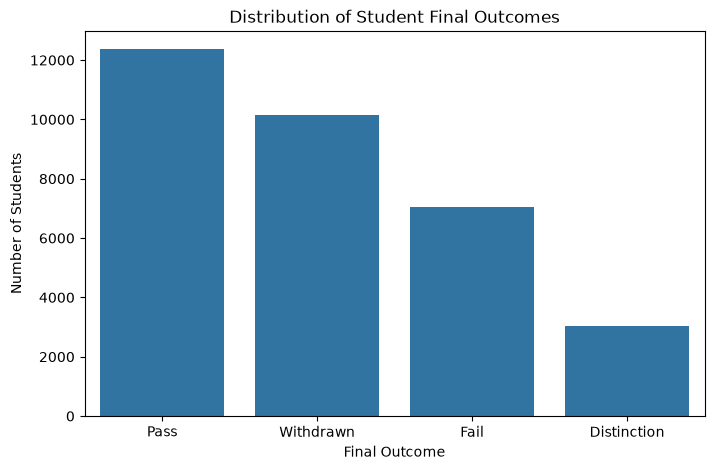

In [32]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=student_info,
    x="final_result",
    order=student_info["final_result"].value_counts().index
)

plt.title("Distribution of Student Final Outcomes")
plt.xlabel("Final Outcome")
plt.ylabel("Number of Students")

plt.show()

In [33]:
course_outcome = pd.crosstab(
    student_info["code_module"],
    student_info["final_result"]
)

course_outcome

final_result,Distinction,Fail,Pass,Withdrawn
code_module,,,,
AAA,44,91,487,126
BBB,677,1767,3077,2388
CCC,498,781,1180,1975
DDD,383,1412,2227,2250
EEE,356,562,1294,722
FFF,670,1711,2978,2403
GGG,396,728,1118,292


In [34]:
course_outcome_percentage = (
    pd.crosstab(
        student_info["code_module"],
        student_info["final_result"],
        normalize="index"
    ) * 100
).round(2)

course_outcome_percentage

final_result,Distinction,Fail,Pass,Withdrawn
code_module,,,,
AAA,5.88,12.17,65.11,16.84
BBB,8.56,22.34,38.91,30.19
CCC,11.23,17.61,26.61,44.54
DDD,6.11,22.51,35.51,35.87
EEE,12.13,19.15,44.10,24.61
FFF,8.63,22.04,38.37,30.96
GGG,15.63,28.73,44.12,11.52


## 6. Day 1 Initial Findings

After exploring the dataset, the following areas will be investigated further:

1. Student outcome distribution.
2. Withdrawal patterns across courses.
3. Relationship between VLE engagement and final results.
4. Assessment participation and academic performance.
5. Student retention over time.
6. Identification of behavioural patterns associated with withdrawal.

### Next Step

Day 2 will focus on data cleaning and preprocessing. Missing values, duplicates, data types, and dataset relationships will be carefully handled before performing advanced analysis.

EdTech-Learning-Analytics
│
├── data
│   ├── raw
│   │   └── All 7 original CSV files
│   │
│   └── processed
│       └── EMPTY
│
└── notebooks
    └── 01_data_understanding.ipynb
        │
        ├── Project Introduction
        ├── Business Problem
        ├── Project Objectives
        ├── Import Libraries
        ├── Load 7 Datasets
        ├── Dataset Summary
        ├── Inspect Each Dataset
        ├── Understand Relationships
        ├── Data Quality Check
        ├── Missing Value Inspection
        └── Initial Outcome Analysis